<a href="https://colab.research.google.com/github/muhammadbinasim33-ui/Business-Data-Text-Mining-Assignments/blob/main/i234600_ecommerce_reviews_A_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Assignment 3: Ecommerce Review and Machine Learning**

# **Task 1: Dataset and Exploration:**
## 1. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re
import html
import json
import unicodedata
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer,ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation,TruncatedSVD
from sklearn.preprocessing import normalize
from nltk.stem import WordNetLemmatizer, PorterStemmer
import spacy
Seed = 42
print ('Libraries imported successfully')

Libraries imported successfully


Load dataset and explore

In [2]:
ecom = pd.read_csv("/content/drive/MyDrive/Womens Clothing E-Commerce Reviews.csv")

Explore

In [3]:
print("shape:",ecom.shape)
display(ecom.head())

shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


Understand the dataset

In [4]:
# dataset structure
ecom.info()
# column names
print(ecom.columns.to_list())
# statistical summary
display(ecom.describe(include = "all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name',

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,23486.0,NaN,NaN,NaN,11742.5,6779.968547,0.0,5871.25,11742.5,17613.75,23485.0
Clothing ID,23486.0,NaN,NaN,NaN,918.118709,203.29898,0.0,861.0,936.0,1078.0,1205.0
Age,23486.0,NaN,NaN,NaN,43.198544,12.279544,18.0,34.0,41.0,52.0,99.0
Title,19676,13993,Love it!,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review Text,22641,22634,Perfect fit and i've gotten so many compliment...,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,23486.0,NaN,NaN,NaN,4.196032,1.110031,1.0,4.0,5.0,5.0,5.0
Recommended IND,23486.0,NaN,NaN,NaN,0.822362,0.382216,0.0,1.0,1.0,1.0,1.0
Positive Feedback Count,23486.0,NaN,NaN,NaN,2.535936,5.702202,0.0,0.0,1.0,3.0,122.0
Division Name,23472,3,General,13850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department Name,23472,6,Tops,10468,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Data Quality

In [5]:
# Missing values
print("Missing values per column:")
display(ecom.isnull().sum().sort_values(ascending = False))
# Duplicate records
print("duplicated rows:",ecom.duplicated().sum())
# Text review length
review_col = "Review Text"
ecom["Review Length"] = ecom[review_col].fillna("").astype(str).str.len()
display(ecom["Review Length"].describe())

Missing values per column:


,0
Title,3810
Review Text,845
Department Name,14
Class Name,14
Division Name,14
Unnamed: 0,0
Clothing ID,0
Age,0
Rating,0
Recommended IND,0


duplicated rows: 0


,Review Length
count,23486.000000
mean,297.581666
std,152.572686
min,0.000000
25%,173.000000
50%,292.000000
75%,451.000000
max,508.000000


First two Vizs

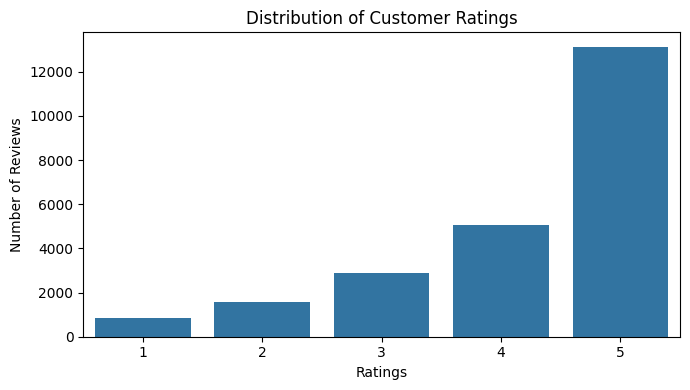

In [6]:
# Visualization 1: Rating Distribution
import seaborn as sns
plt.figure(figsize= (7,4))
sns.countplot(data = ecom,x= 'Rating')
plt.title("Distribution of Customer Ratings")
plt.xlabel("Ratings")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

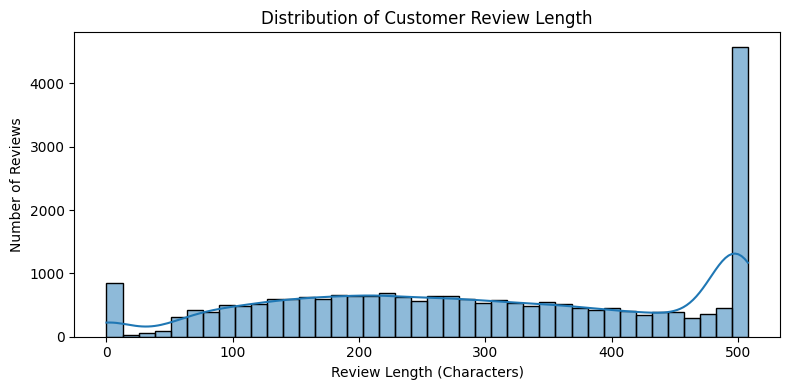

In [7]:
# Visualization 2: Review Length distribution
plt.figure(figsize= (8,4))
sns.histplot(ecom["Review Length"], bins = 40,kde = True)
plt.title("Distribution of Customer Review Length")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

## Interpretation of dataset exploration:
The dataset contains 23,486 customer reviews collected from the Women's E-comerce Clothing Reviews dataset on Kaggle. It includes product categories, customer review-text, ratings, age and recommendation information.
### Data Quality:
The dataset contained 3810 missing values in Title column, 645 in review-text column and 14 each in department name, Class name and division name. There were no duplicate records identified. As review text is essential for text mining we therefore removed missing review-text records.
### Review Length Distribution:
The average review length is approximately 298 characters, with a median of 292 characters. The minimum length is zero and maximum is 508 characters.
This indicates that customers provide reviews of varying lengths, with many offering descriptive feedback about their clothing purchases.
### Visualization Findings:
The rating distribution visualization helps identify the overall pattern of customer satisfaction across the five rating categories.
The review length distribution(histogram) shows the variation in the amount of feedback provided by customer.
Overall, the dataset provides useful information for understanding customer satisfaction and identify areas of product improvement.  

In [8]:
# Create copy of the original
ecom_original = ecom.copy()
# Create a working copy
ecom_clean = ecom_original.copy()
print("Shape of original dataset:",ecom_original.shape)
print("Shape of working copy:",ecom_clean)

Shape of original dataset: (23486, 12)
Shape of working copy:        Unnamed: 0  Clothing ID  Age  \
0               0          767   33   
1               1         1080   34   
2               2         1077   60   
3               3         1049   50   
4               4          847   47   
...           ...          ...  ...   
23481       23481         1104   34   
23482       23482          862   48   
23483       23483         1104   31   
23484       23484         1084   28   
23485       23485         1104   52   

                                                   Title  \
0                                                    NaN   
1                                                    NaN   
2                                Some major design flaws   
3                                       My favorite buy!   
4                                       Flattering shirt   
...                                                  ...   
23481                     Great dress for many oc

## **Task 2: Text cleaning and Preprocessing**

### Step 1: Handle missing values

In [9]:
# Remove rows where review text is missing
ecom_clean = ecom_clean.dropna(subset=['Review Text']).copy()
# Fill missing titles
ecom_clean['Title']= ecom_clean['Title'].fillna("")

print("Original dataset:",ecom_original.shape)
print("Working copy after removing missing reviews:",ecom_clean.shape)

print("\n Remaing missing values:")
print(ecom_clean[["Review Text","Title"]].isnull().sum())


Original dataset: (23486, 12)
Working copy after removing missing reviews: (22641, 12)

 Remaing missing values:
Review Text    0
Title          0
dtype: int64


# Step 2: Clean the text

In [10]:
def clean_text(text):
  text = str(text).lower()
  # Remove urls
  text = re.sub(r'https?://\S+|www\.\S+',"",text)
  # Remove html tags
  text = re.sub(r"<[^>]+>","",text)
  # Remove punctuations and special characters
  text = re.sub(r"[^a-z\s]"," ",text)
  # Remove extra space
  text = re.sub(r"\s+"," ",text).strip()
  return text
ecom_clean['Cleaned Review'] = ecom_clean["Review Text"].apply(clean_text)
# Compare original and cleaned reviews
display(ecom_clean[["Review Text","Cleaned Review"]].head(5))


,Review Text,Cleaned Review
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...
1,Love this dress! it's sooo pretty. i happene...,love this dress it s sooo pretty i happened to...
2,I had such high hopes for this dress and reall...,i had such high hopes for this dress and reall...
3,"I love, love, love this jumpsuit. it's fun, fl...",i love love love this jumpsuit it s fun flirty...
4,This shirt is very flattering to all due to th...,this shirt is very flattering to all due to th...


## Step 3 Tokenization and removal of Stopwords

In [11]:
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))
# Tokenize and remove
ecom_clean["Tokens"] = ecom_clean["Cleaned Review"].apply(lambda text: [word for word in wordpunct_tokenize(text) if word not in stop_words])
display(ecom_clean[["Cleaned Review",'Tokens']].head(5))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Cleaned Review,Tokens
0,absolutely wonderful silky and sexy and comfor...,"[absolutely, wonderful, silky, sexy, comfortable]"
1,love this dress it s sooo pretty i happened to...,"[love, dress, sooo, pretty, happened, find, st..."
2,i had such high hopes for this dress and reall...,"[high, hopes, dress, really, wanted, work, ini..."
3,i love love love this jumpsuit it s fun flirty...,"[love, love, love, jumpsuit, fun, flirty, fabu..."
4,this shirt is very flattering to all due to th...,"[shirt, flattering, due, adjustable, front, ti..."


## Step 4: Stemming

In [12]:
stemmer = PorterStemmer()
ecom_clean["Stemmed Tokens"] = ecom_clean["Tokens"].apply(lambda tokens:[stemmer.stem(word)for word in tokens])
display(ecom_clean[["Tokens","Stemmed Tokens"]].head(5))

,Tokens,Stemmed Tokens
0,"[absolutely, wonderful, silky, sexy, comfortable]","[absolut, wonder, silki, sexi, comfort]"
1,"[love, dress, sooo, pretty, happened, find, st...","[love, dress, sooo, pretti, happen, find, stor..."
2,"[high, hopes, dress, really, wanted, work, ini...","[high, hope, dress, realli, want, work, initi,..."
3,"[love, love, love, jumpsuit, fun, flirty, fabu...","[love, love, love, jumpsuit, fun, flirti, fabu..."
4,"[shirt, flattering, due, adjustable, front, ti...","[shirt, flatter, due, adjust, front, tie, perf..."


### Step 5: Ten most frequent words and five most frequent bigrams

In [13]:
from collections import Counter
from nltk.util import ngrams
## Combine tokens across all reviews
all_tokens =[word for tokens in ecom_clean["Stemmed Tokens"]for word in tokens]
# Ten most frequent words
word_counts = Counter(all_tokens)
print("Top 10 most frequent words:")
display(pd.DataFrame(word_counts.most_common(10),columns=["Word","Frequency"]))

Top 10 most frequent words:


,Word,Frequency
0,dress,12187
1,fit,11514
2,love,11395
3,size,10723
4,look,9354
5,top,8375
6,wear,8075
7,like,7876
8,color,7300
9,great,6118


## Bigrams

In [14]:
## Five most frequent bigrams
all_bigrams =[bigram for tokens in ecom_clean["Tokens"]for bigram in ngrams(tokens,2)]
bigrams_count = Counter(all_bigrams)
print("Top 5 most frequent bigrams")
display(pd.DataFrame([(" ".join(bigram),count)for bigram,count in bigrams_count.most_common(5)],columns=["Bigram","Frequency"]))

Top 5 most frequent bigrams


,Bigram,Frequency
0,true size,1347
1,love dress,734
2,usually wear,690
3,looks great,622
4,well made,607


## Interpretation of Text Preprocessing
Text Preprocessing was performed to convert unstructured customer reviews into well defined format suitable for text mining. The process included removal of urls, html tags, unnecessary characters, tokenization, stop-word removal, and lower-case conversion.
### Most frequent word analysis
The most frequent words in the dataset were dress,fit, love, size,and look. This indicates that customers frequently discuss clothing appearances,fitting, sizing,and overall product experiences.
### Bigrams Analysis
The most frequent bigrams include "true size","love dress", "usually wear","looks great" and "well made". These combinations provide additional context about customer feedback like "true size" indicates discussions about sizing accuracy while "well made" reflects about product quality.
Overall, preprocessing helped transform customers reviews into a structured textual format for further analysis.  

# Task 3: Text Representation and feature extraction
## 3.1 Bag of Words

In [15]:
texts = ecom_clean["Cleaned Review"].fillna("")
bow_vectorizer = CountVectorizer(max_features = 1000)
X_bow = bow_vectorizer.fit_transform(texts)
print("BOW Matrix shape",X_bow.shape)
## Display a sample of the vocabulary
print("\n First 20 vocabulary words")
print(bow_vectorizer.get_feature_names_out()[:20])
## Display first 5 reviews and 15 features
bow_sample = pd.DataFrame(X_bow[:5, :15].toarray(),columns = bow_vectorizer.get_feature_names_out()[:15])
display(bow_sample)

BOW Matrix shape (22641, 1000)

 First 20 vocabulary words
['able' 'about' 'above' 'absolutely' 'across' 'actually' 'add' 'added'
 'addition' 'adds' 'adorable' 'adore' 'afraid' 'after' 'ag' 'again'
 'against' 'ago' 'agree' 'airy']


,able,about,above,absolutely,across,actually,add,added,addition,adds,adorable,adore,afraid,after,ag
0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
tfidf_vectorizer = TfidfVectorizer(max_features=1000)
X_tfidf = tfidf_vectorizer.fit_transform(texts)
print("TF-IDF matrix shape:",X_tfidf.shape)
## Display tfidf sample
tfidf_sample = pd.DataFrame(X_tfidf[:5, :15].toarray(),columns = tfidf_vectorizer.get_feature_names_out()[:15])
display(tfidf_sample)

TF-IDF matrix shape: (22641, 1000)


,able,about,above,absolutely,across,actually,add,added,addition,adds,adorable,adore,afraid,after,ag
0,0.0,0.0,0.0,0.3775,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Cosaine Similarity for three pairs of review

In [17]:
pairs = [(0,1),(2,3),(4,5)]
results = []
for i,j in pairs:
  bow_score = cosine_similarity(X_bow[i],X_bow[j])[0,0]
  tfidf_score = cosine_similarity(X_tfidf[i],X_tfidf[j])[0,0]
  results.append({"Review Pair": f"{i} and {j}", "BOW Similarity": round(bow_score,4), "TF-IDF Similarity": round(tfidf_score,4)})

display(pd.DataFrame(results))

,Review Pair,BOW Similarity,TF-IDF Similarity
0,0 and 1,0.1550,0.0188
1,2 and 3,0.2410,0.0458
2,4 and 5,0.4495,0.1671


### Comparison B/w BOW and TF-IDF

In [18]:
comparison = pd.DataFrame({'Feature ':["Representation","Word values","Common Words","Main advantage ","Main limitation"],"Bag of Words":
                           ["Word count vectors","Raw word counts","Can dominate due to frequency","Simple and easy to interpret","Does not account for word importance"],
                           "TF-IDF":["Weighted word vectors","Importance scores","Often recieve lower weights","Highlights more destinctive terms","Does not understand meaning or context"]})
display(comparison)

,Feature,Bag of Words,TF-IDF
0,Representation,Word count vectors,Weighted word vectors
1,Word values,Raw word counts,Importance scores
2,Common Words,Can dominate due to frequency,Often recieve lower weights
3,Main advantage,Simple and easy to interpret,Highlights more destinctive terms
4,Main limitation,Does not account for word importance,Does not understand meaning or context


## Interpretation of Text Representation and Feature Extraction
### Bag of Words
Bag of words converted customer reviews into numerical vectors based on word frequency. The resulting feature matrix contain 22,641 reviews and 1000 vocabulary features. Each value represent the frequency of a particular word in a review.
#### TF-IDF
TF-IDF also generated a matrix of 22,641 reviews and 1000 features. Unlike BOW, it assigns weights to words according to their importance within the collection of reviews. Words that occur frequently across many reviews generally recieve lower weights while more distinctive words may recieve importance.
#### Cossine Similarity:
Cosine similarity was calculated for three pair of reviews. The third pair(reviews 4 and 5) achieved  higher similarity with both methods (BOW) and (TF-IDF) with scores of 0.4495 and 0.1671. This suggest that the third pair of reviews had more vocabulary than the other selected pairs.
### Comparison of BOW and TF-IDF
Bag of words is simple and useful for understanding word frequencies. However, it does not consider the relative importance of words.
TF-IDF is more useful for identifying distinctive terms because it reduces the influence of very common words. Therefore TF-IDF is more suitable for identifying customer concerns whereas BOW is good at identifying word frequency.



#Task 4 Sentiment analysis and Classification

### Step 4.1: Lexicon based sentiment analysis

In [19]:
from nltk.sentiment import SentimentIntensityAnalyzer
nltk.download("vader_lexicon")
sia = SentimentIntensityAnalyzer()
print("VADER initialized successfully")

VADER initialized successfully


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


## Step 4.2 Classify Customer Reviews

In [20]:
# calculate Vader sentiment scores
ecom_clean["VADER Score"]=ecom_clean["Review Text"].apply(lambda text:sia.polarity_scores(str(text))["compound"])
# Assign sentiment labels
def classify_sentiment(score):
  if score >= 0.05:
    return "positive"
  elif score <= -0.05:
    return "Negative"
  else:
    return "Neutral"
ecom_clean["VADER Sentiment"] = ecom_clean["VADER Score"].apply(classify_sentiment)
# display sample results
display(ecom_clean[["Review Text","VADER Score","VADER Sentiment"]].head(10))


,Review Text,VADER Score,VADER Sentiment
0,Absolutely wonderful - silky and sexy and comf...,0.8932,positive
1,Love this dress! it's sooo pretty. i happene...,0.9729,positive
2,I had such high hopes for this dress and reall...,0.9427,positive
3,"I love, love, love this jumpsuit. it's fun, fl...",0.5727,positive
4,This shirt is very flattering to all due to th...,0.9291,positive
5,"I love tracy reese dresses, but this one is no...",0.9419,positive
6,I aded this in my basket at hte last mintue to...,0.8004,positive
7,"I ordered this in carbon for store pick up, an...",-0.0909,Negative
8,I love this dress. i usually get an xs but it ...,0.7175,positive
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",-0.3724,Negative


### Step 4.3: Vizualize Sentiment Distribution

Sentiment Distribution:


,Number of Reviews
VADER Sentiment,
positive,20987
Negative,1377
Neutral,277


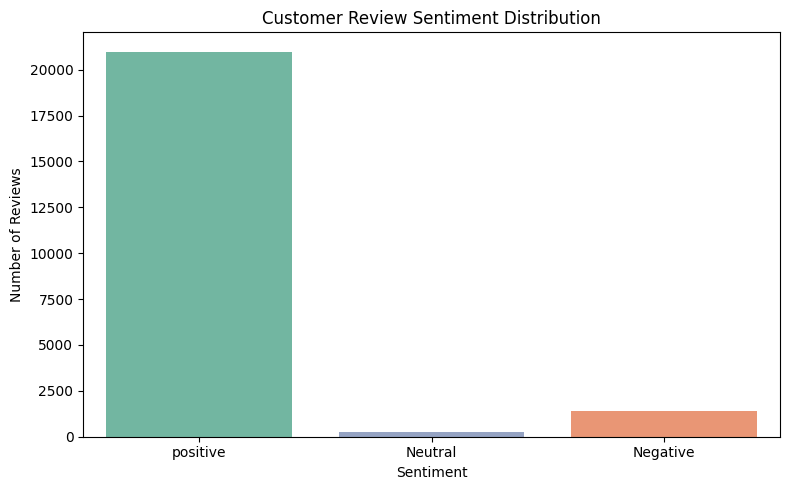

In [21]:
sentiment_counts = ecom_clean["VADER Sentiment"].value_counts()
print("Sentiment Distribution:")
display(sentiment_counts.to_frame("Number of Reviews"))

plt.figure(figsize=(8,5))
sns.countplot(
    data=ecom_clean,
    x="VADER Sentiment",
    order=["positive", "Neutral", "Negative"],
    hue="VADER Sentiment",
    palette="Set2",
    legend=False
)
plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [22]:
def rating_to_sentiment(rating):
  if rating <= 2:
    return "Negative"
  elif rating == 3:
    return "Neutral"
  else:
    return "Positive"
ecom_clean ["Sentiment Label"] = ecom_clean["Rating"].apply(rating_to_sentiment)
print("Rating based sentiment distribution:")
display(ecom_clean["Sentiment Label"].value_counts().to_frame("Reviews"))

Rating based sentiment distribution:


,Reviews
Sentiment Label,
Positive,17448
Neutral,2823
Negative,2370


### Step 4.5: Prepare Train and Test Data

In [23]:
## Input Features and target feature
X= ecom_clean["Cleaned Review"]
y= ecom_clean["Sentiment Label"]
## Split the dataset
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:",len(X_train))
print("Testing samples:",len(X_test))
print("Training Sentiment distribution")
print(y_train.value_counts())
print("Testing Sentiment Distribution:")
print(y_test.value_counts())

Training samples: 18112
Testing samples: 4529
Training Sentiment distribution
Sentiment Label
Positive    13958
Neutral      2258
Negative     1896
Name: count, dtype: int64
Testing Sentiment Distribution:
Sentiment Label
Positive    3490
Neutral      565
Negative     474
Name: count, dtype: int64


## Step 4.6: Apply TF-IDF Vectorization for training data

In [24]:
tfidf_ml = TfidfVectorizer(max_features=5000)
## Fit on training data and transform both sets
X_train_tfidf = tfidf_ml.fit_transform(X_train)
X_test_tfidf = tfidf_ml.transform(X_test)
print("Training shape:",X_train_tfidf.shape)
print("Testing shape:",X_test_tfidf.shape)

Training shape: (18112, 5000)
Testing shape: (4529, 5000)


## Step 4.7 Apply Naive Bayes algorithm

In [25]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf,y_train)
### Predictions
nb_pred = nb_model.predict(X_test_tfidf)
print("Naive Bayes Training completed!")

Naive Bayes Training completed!


### Step 4.8: Apply Logistic Regression

In [26]:
lr_model = LogisticRegression(max_iter = 1000,random_state=42)
lr_model.fit(X_train_tfidf,y_train)
## make predictions
lr_pred = lr_model.predict(X_test_tfidf)
print("Logistic Regression Training completed!")

Logistic Regression Training completed!


### 4.9 Evaluate Both Models

In [27]:
from sklearn.metrics import recall_score, precision_score
## NB Evaluations
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred, average="weighted")
nb_recall = recall_score(y_test, nb_pred, average="weighted")
nb_f1 = f1_score(y_test, nb_pred, average="weighted")
### Logistic Regression Evaluations
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, average="weighted")
lr_recall = recall_score(y_test, lr_pred, average="weighted")
lr_f1 = f1_score(y_test, lr_pred, average="weighted")
## Created comparison table:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [nb_accuracy, lr_accuracy],
    "Precision": [nb_precision, lr_precision],
    "Recall": [nb_recall, lr_recall],
    "F1 Score": [nb_f1, lr_f1]
})
## Display Results
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.7777,0.7745,0.7777,0.6882
1,Logistic Regression,0.8273,0.7974,0.8273,0.8050


## 4.10: Generate confusion matrices

#### 4.10.1 Naive Bayes Confusion Matrix

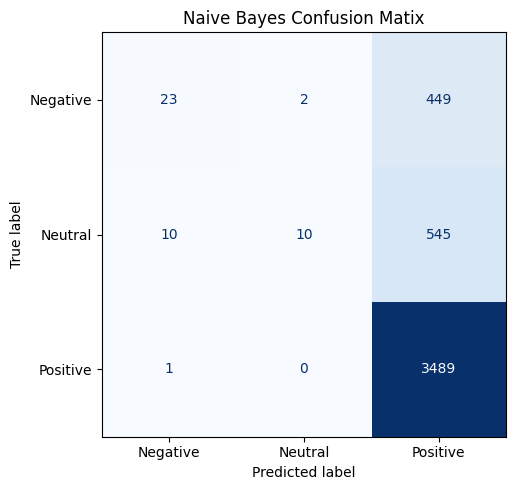

In [28]:
from sklearn.metrics import confusion_matrix
labels = ["Negative","Neutral","Positive"]
# Naive Bayes Confusion matrix
cm_nb = confusion_matrix(y_test,nb_pred, labels = labels)
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb,display_labels = labels)
fig,ax = plt.subplots(figsize =(6,5))
disp_nb.plot(ax=ax,cmap = "Blues",colorbar = False)
plt.title("Naive Bayes Confusion Matix")
plt.tight_layout()
plt.show()


#### 4.10.2 Logistic Regression Confusion Matrix

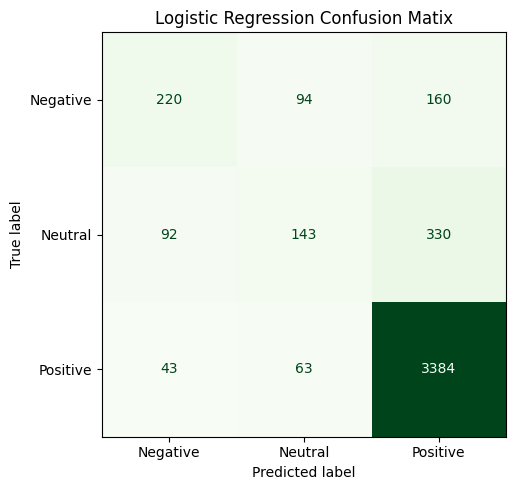

In [29]:
### Logistic Regresssion Confusion Matrix
cm_lr = confusion_matrix(y_test,lr_pred, labels = labels)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr,display_labels = labels)
fig, ax = plt.subplots(figsize=(6,5))
disp_lr.plot(ax=ax,cmap = "Greens",colorbar = False)
plt.title("Logistic Regression Confusion Matix")
plt.tight_layout()
plt.show()

### Step 11: Detailed Classification Reports

In [30]:
print("Naive Bayes Classification Report")
print(classification_report(y_test,nb_pred,labels = labels))

print("Logistic Regression Classification Report")
print(classification_report(y_test,lr_pred,labels=labels))


Naive Bayes Classification Report
              precision    recall  f1-score   support

    Negative       0.68      0.05      0.09       474
     Neutral       0.83      0.02      0.03       565
    Positive       0.78      1.00      0.88      3490

    accuracy                           0.78      4529
   macro avg       0.76      0.36      0.33      4529
weighted avg       0.77      0.78      0.69      4529

Logistic Regression Classification Report
              precision    recall  f1-score   support

    Negative       0.62      0.46      0.53       474
     Neutral       0.48      0.25      0.33       565
    Positive       0.87      0.97      0.92      3490

    accuracy                           0.83      4529
   macro avg       0.66      0.56      0.59      4529
weighted avg       0.80      0.83      0.81      4529



### Step 4.12 Compare the Models

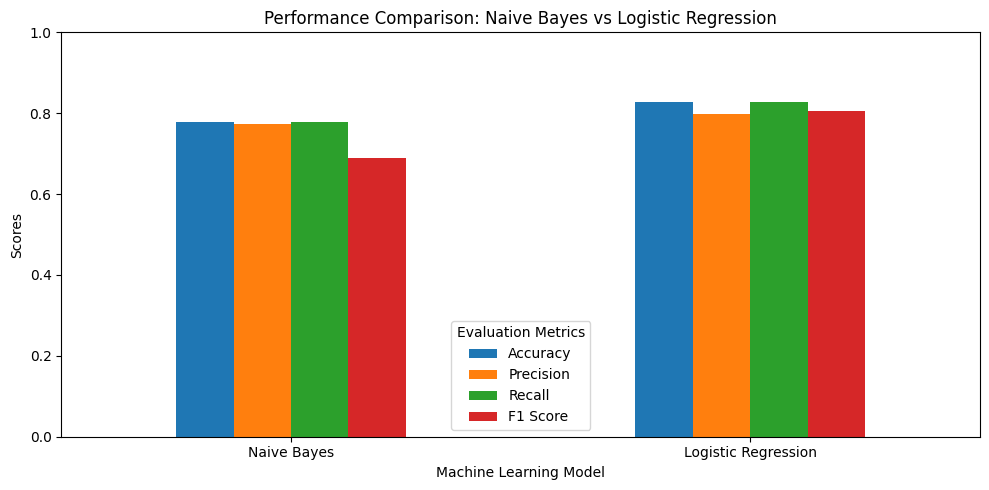

In [31]:
## Visual comparison of evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
results_plot = results.set_index("Model")[metrics]
results_plot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
plt.title("Performance Comparison: Naive Bayes vs Logistic Regression")
plt.ylabel("Scores")
plt.xlabel("Machine Learning Model")
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

## Interpretation of Sentiment Analysis and Classification
### Lexicon-Based Sentiment Analysis
VADER was used to classify customer reviews into Positive, neutral and Negative categories. The result show that 20,987 reviews were classified as positive, 277 as neutral and 1,377 as negative. This indicates that the majority reviews were positive while some of the customers show dissatisfaction.
### Rating based sentiment analysis
Customer ratings were converted into sentiment labels:
*   Rating 1 and 2: Negative
*   Rating 3: Neutral
*   Rating 4 and 5: Positive
The resulting distribution contained 17,448 positive reviews, 2823 neutral reviews and 2370 negative reviews.
The difference between results of VADER and rating based results show that sentiment expressed through language differ from sentiment infered from numerical ratings.
### Model Evaluation
Two supervised machine learning models Naive Bayes and Logistic Regression were trained using TF-IDF Features.
Logistic Regression achieved an accuracy of 82.73%, compared with 77.77% of Naive Bayes. It also achieved 80.50% weighted F1-Score and higher wieghted precision of 79.74%.
### Confusion Matrix and Classification Reports
The confusion matrices show the correct and incorrect predictions by both models. Logistic Regression performed much better at identifying neutral and negative reviews compared to Naive Bayes. Both of the models achieved there strongest performance while classifying positive reviews. The results also clarify that classifying neutral reviews were difficult.
### Model Recommendation
Based on the evaluation results, Logistic regression is the better performing model in this experiment. However its classification performance on neutral and negative reviews may need room for improvement.
The company should consider techniques like class balancing, additional feature engineering, and further model optimization to improve the identification of less frequent sentiment categories.





## Task 5: Business Insights and Recomendations

### Step 5.1 Identify common customer complaints

In [32]:
# Select negative reviews
negative_reviews = ecom_clean[ecom_clean["Sentiment Label"]=="Negative"]
# Combine negative review
negative_text = " ".join(negative_reviews["Cleaned Review"])
# Split into individual words
negative_words = negative_text.split()
# Count negative words
negative_count = Counter(negative_words)
# Display top 10 words
print("Top 10 Customer Complaints:")
display(pd.DataFrame(
negative_count.most_common(10),
    columns=["Word", "Frequency"]
))


Top 10 Customer Complaints:


,Word,Frequency
0,the,9162
1,i,6727
2,it,5327
3,and,4689
4,a,3819
5,this,2851
6,is,2776
7,to,2581
8,was,2380
9,in,2151


### Step 5.2 Identify Positive Customer Feedback

In [33]:
# Select positive reviews
positive_reviews = ecom_clean[ecom_clean["Sentiment Label"]=="Positive"]["Cleaned Review"].dropna()
## Extract frequent words and Phrases
positive_vectorizer = CountVectorizer(stop_words= "english",ngram_range=(1,2),min_df=5,max_features=30)
positive_matrix = positive_vectorizer.fit_transform(positive_reviews)
## Calculate Frequencies
positive_counts = positive_matrix.sum(axis=0).A1
## Create results table
positive_results = pd.DataFrame({"Positive Feedback":positive_vectorizer.get_feature_names_out(),"Frequency":positive_counts})
positive_results = positive_results.sort_values(by="Frequency",ascending=False)
display(positive_results.head(15))

,Positive Feedback,Frequency
6,dress,8036
21,love,7742
26,size,7081
8,fit,5631
29,wear,5422
12,great,5417
17,like,4929
14,just,4011
3,color,3634
27,small,3531


### Step 5.3 Customer Satisfaction By Department

In [35]:
## Group Reviews by department
department_analysis = ecom_clean.groupby("Department Name").agg(Total_Reviews =("Rating","count"),Average_Rating =("Rating","mean"),Recommendation_Rate=("Recommended IND","mean")).reset_index()
## Round average rating
department_analysis["Average_Rating"]= (department_analysis["Average_Rating"].round(2))
## Convert recommendation rate to percentage
department_analysis["Recommendation_Rate"]=(department_analysis["Recommendation_Rate"]*100).round(2)
display(department_analysis)

,Department Name,Total_Reviews,Average_Rating,Recommendation_Rate
0,Bottoms,3662,4.28,84.95
1,Dresses,6145,4.14,80.52
2,Intimate,1653,4.27,84.63
3,Jackets,1002,4.25,83.33
4,Tops,10048,4.16,81.07
5,Trend,118,3.84,74.58


## Step 5.4: Visualize average ratings


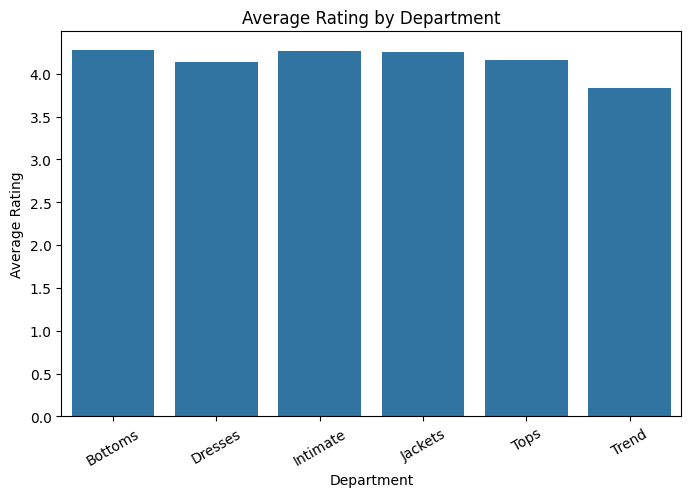

In [37]:
plt.figure(figsize=(8,5))
sns.barplot(data=department_analysis,x="Department Name",y="Average_Rating")
plt.title("Average Rating by Department")
plt.xlabel("Department")
plt.ylabel("Average Rating")
plt.xticks(rotation=30)
plt.show()

### Step 5.5: Visualize recomendation rates

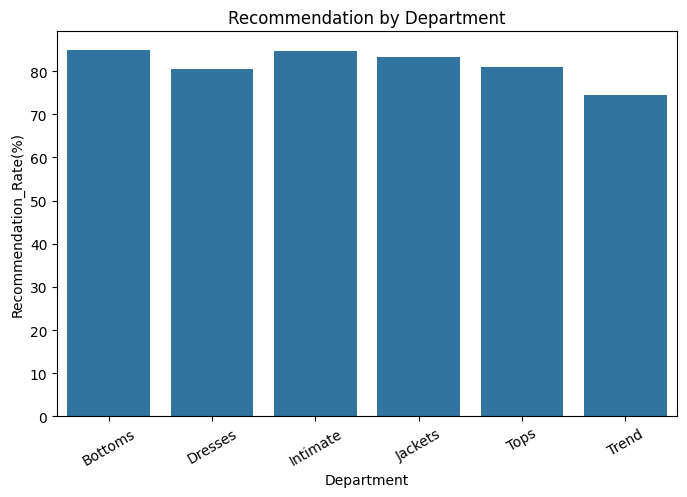

In [38]:
plt.figure(figsize=(8,5))
sns.barplot(data=department_analysis,x="Department Name",y="Recommendation_Rate")
plt.title("Recommendation by Department")
plt.xlabel("Department")
plt.ylabel("Recommendation_Rate(%)")
plt.xticks(rotation=30)
plt.show()

### Step 5.6 Highest and Lowest rated departments

In [40]:
## Highest rated departments
best = department_analysis.loc[department_analysis["Average_Rating"].idxmax()]
# Lowest rated departments
worst = department_analysis.loc[department_analysis["Average_Rating"].idxmin()]
print("Highest rated Departments:")
print(best[["Department Name","Average_Rating"]])
print("Lowest rated Departments:")
print(worst[["Department Name","Average_Rating"]])




Highest rated Departments:
Department Name    Bottoms
Average_Rating        4.28
Name: 0, dtype: object
Lowest rated Departments:
Department Name    Trend
Average_Rating      3.84
Name: 5, dtype: object


### Step 5.7: Final Business Insight

In [44]:
print("Business Insight")
print("\n1. Common Customer Complaints:")
print(negative_count.most_common(5))

print("\n2. Positive Customer Feedback:")
print(positive_results.head(5))

print("\n3. Highest-rated Department:")
print(best["Department Name"])

print("\n4. Lowest-rated Department:")
print(worst["Department Name"])


Business Insight

1. Common Customer Complaints:
[('the', 9162), ('i', 6727), ('it', 5327), ('and', 4689), ('a', 3819)]

2. Positive Customer Feedback:
   Positive Feedback  Frequency
6              dress       8036
21              love       7742
26              size       7081
8                fit       5631
29              wear       5422

3. Highest-rated Department:
Bottoms

4. Lowest-rated Department:
Trend


### Interpretation of Task 5:
Common Customer complaints of the data had negative counts 9167, 6727, 5327, and so on. The words that include positive feedback in the following words dress,love,size,fit, wear. The highest rated department was Bottoms and the lowest rated was Trend.

### **THE END !**